In [2]:
import sys
sys.path.append("../src")

import numpy as np
from outcomes import simulate_fund, net_tvpi

print("Base:", np.mean([simulate_fund(30) for _ in range(2000)]).round(2))
print("Skilled:", np.mean([simulate_fund(30, "skilled") for _ in range(2000)]).round(2))

Base: 2.78
Skilled: 4.75


In [3]:
sizes = [5, 10, 15, 30, 50, 100, 200]

for scenario in ["base", "skilled"]:
    print("---", scenario, "---")
    for n in sizes:
        net = np.array([net_tvpi(simulate_fund(n, scenario)) for _ in range(5000)])
        print(n, "startups | mean net:", net.mean().round(2),
              "| P(<1x):", (net < 1).mean().round(3),
              "| P(3x):", (net >= 3).mean().round(3))

--- base ---
5 startups | mean net: 1.94 | P(<1x): 0.459 | P(3x): 0.15
10 startups | mean net: 1.92 | P(<1x): 0.368 | P(3x): 0.186
15 startups | mean net: 1.95 | P(<1x): 0.282 | P(3x): 0.199
30 startups | mean net: 1.98 | P(<1x): 0.156 | P(3x): 0.161
50 startups | mean net: 1.97 | P(<1x): 0.079 | P(3x): 0.119
100 startups | mean net: 1.97 | P(<1x): 0.019 | P(3x): 0.052
200 startups | mean net: 1.99 | P(<1x): 0.001 | P(3x): 0.017
--- skilled ---
5 startups | mean net: 3.32 | P(<1x): 0.331 | P(3x): 0.324
10 startups | mean net: 3.24 | P(<1x): 0.189 | P(3x): 0.411
15 startups | mean net: 3.24 | P(<1x): 0.115 | P(3x): 0.455
30 startups | mean net: 3.18 | P(<1x): 0.028 | P(3x): 0.491
50 startups | mean net: 3.22 | P(<1x): 0.005 | P(3x): 0.53
100 startups | mean net: 3.22 | P(<1x): 0.0 | P(3x): 0.566
200 startups | mean net: 3.22 | P(<1x): 0.0 | P(3x): 0.624


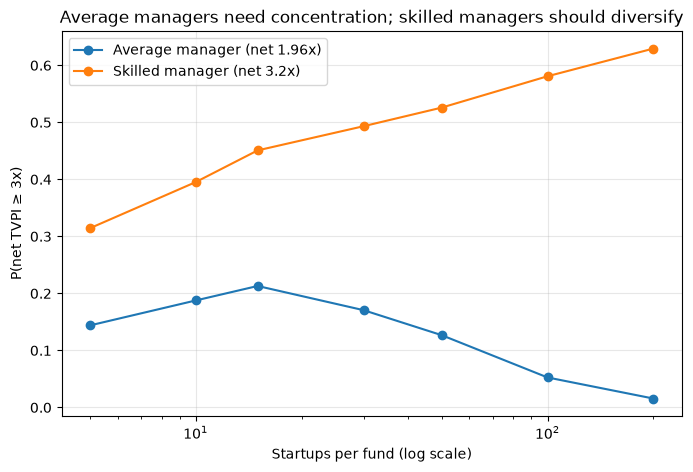

In [4]:
import matplotlib.pyplot as plt

results = {}
for scenario in ["base", "skilled"]:
    p3 = []
    for n in sizes:
        net = np.array([net_tvpi(simulate_fund(n, scenario)) for _ in range(5000)])
        p3.append((net >= 3).mean())
    results[scenario] = p3

plt.figure(figsize=(8, 5))
plt.plot(sizes, results["base"], marker="o", label="Average manager (net 1.96x)")
plt.plot(sizes, results["skilled"], marker="o", label="Skilled manager (net 3.2x)")
plt.xscale("log")
plt.xlabel("Startups per fund (log scale)")
plt.ylabel("P(net TVPI ≥ 3x)")
plt.title("Average managers need concentration; skilled managers should diversify")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../results/phase5_strategy.png", dpi=150, bbox_inches="tight")
plt.show()

## What this means

**Question.** Should a fund concentrate on a few startups or diversify? We compare an average manager (Correlation Ventures base case, 4% home runs) with a skilled manager (9% home runs, Vlerick survey), net of fees and carry.

**Findings.**
- Skill matters more than anything else: 5 extra points of home runs lift gross TVPI from 2.78x to 4.75x, and net TVPI from 1.96x to about 3.2x.
- The average manager maximises the chance of 3x net with about 15 startups (20%), at the cost of a 28% chance of losing money. With 100 startups, the chance of 3x falls to 5%.
- For the skilled manager, the chance of 3x keeps rising with diversification, from 46% with 15 startups to 62% with 200.

**The rule.** If your expected multiple is below the target, you need variance, so concentrate. If it is above, variance is only risk, so diversify.

**Limitations.** The model assumes skill is constant at any portfolio size. In reality, good deals are scarce, smaller tickets mean smaller ownership, and partners have limited time, so a skilled manager cannot keep the same hit rate across 200 companies. The 9% home-run rate comes from a self-reported survey and is likely optimistic.